In [19]:
from pathlib import Path
import pandas as pd
import numpy as np
import pynbody
import matplotlib.pyplot as plt
import warnings

ROMULUS = Path('/mnt/data0/pkrsnak/romulus')
manifest = pd.read_csv(ROMULUS / 'runs' / 'MANIFEST.csv')

In [8]:
def snapshot_path(row):
    run = Path(row.real_path)
    step = str(row.step).zfill(6)
    hits = sorted(run.glob(f'*.{step}')) or sorted(run.glob(f'*.{step}.tipsy'))
    if len(hits) == 1 and hits[0].is_dir():
        hits = [h for h in hits[0].glob(f'*.{step}') if h.is_file()]
    assert len(hits) == 1, (row.key, hits)
    return hits[0]

In [28]:
row = manifest[manifest.key == 'r431_BH'].iloc[0]

s = pynbody.load(str(snapshot_path(row)))
s.physical_units()
print(s.properties['boxsize'])
del s.properties['boxsize']  # otherwise pynbody will try to convert units

if (snapshot_path(row).parent / f"{snapshot_path(row).name}.amiga.grp").exists():
    h = s.halos()
    target = h[1]
else:
    target = s            # tal shiar cutouts only have one halo

#pynbody.analysis.halo.center(target, mode='hyb')
pynbody.analysis.angmom.faceon(target, mode='hyb')

#print(target.s['pos'].mean(axis=0), target['pos'].units)

2.50e+04 kpc


In [29]:
stars = target.s[target.s['tform'] > 0]
bhs   = target.s[target.s['tform'] < 0]

#print((stars['tform'] < 0).sum())
#print((stars['massform'] <= 0).sum())


2777645 True


/mnt/data0/anaconda3/lib/python3.12/site-packages/pynbody/analysis/luminosity.py:114: RuntimeWarning: invalid value encountered in log10
  np.log10(simstars['massform'].in_units('Msol'))


Text(0.5, 0.98, 'r431_BH  step 4096  —  4 BH, max 5.9e+05 Msol')

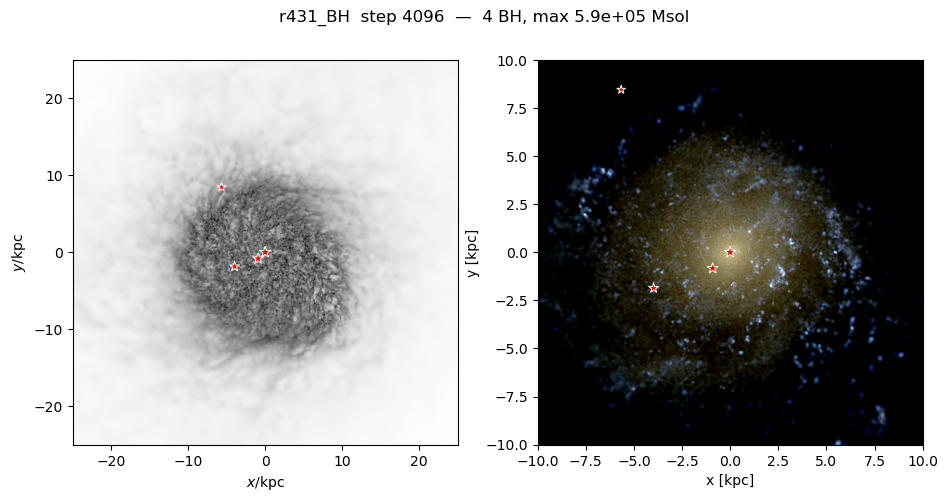

In [30]:
fig, (ax_gas, ax_star) = plt.subplots(1, 2, figsize=(11, 5))

print(len(target.g), np.isfinite(target.g['pos']).all())

pynbody.plot.sph.image(target.g, qty='rho', width='50 kpc',
                       units='Msol kpc^-2', cmap='Greys',
                       subplot=ax_gas, show_cbar=False, 
                       clear=False)

pynbody.plot.stars.render(stars, width=20, axes=ax_star, clear=False)

for ax in (ax_gas, ax_star):
    ax.scatter(bhs['x'], bhs['y'], marker='*', s=40 + 40*np.log10(bhs['mass']/1e5),
               c='red', edgecolors='white', linewidths=0.7, zorder=10)

fig.suptitle(f"{row.key}  step {row.step}  —  {len(bhs)} BH, "
             f"max {bhs['mass'].max():.1e} Msol" if len(bhs) else f"{row.key} — no BH")

In [ ]:
#print(np.isnan(s.s['v_mag']).sum(), len(bhs))          # should match
#print(np.isnan(stars['v_mag']).sum())                   # should be 0
#print(bhs['massform'])                                  # the values that tripped log10

5 4
0
[-3313.85290693 -3313.85290693 -3313.85290693 -3313.85290693]


In [23]:
all_bh = s.s[s.s['tform'] < 0]
r = np.sqrt((all_bh['pos']**2).sum(axis=1))
for i, m, ri in zip(all_bh['iord'], all_bh['mass'], r):
    print(f"{i:>10d}  {m:9.2e} Msol  {ri:7.1f} kpc")

  30558157   4.77e+05 Msol      1.6 kpc
  30558409   5.91e+05 Msol      0.0 kpc
  30559342   1.09e+05 Msol     11.6 kpc
  30559443   2.32e+05 Msol      4.5 kpc
  30600854   1.13e+05 Msol     21.0 kpc
